# Does a late delivery cost a repeat customer?

**Data:** Olist, a Brazilian e-commerce marketplace: about 99k orders and 96k customers (2016–2018), from Olist's own public data repository.

**Question:** If a customer's *first* order arrives late, are they less likely to buy again?

**Answer, in short:** Yes, but the lost revenue from fewer repeat orders is small. A late first order cuts the odds of a repeat purchase by about 28%. It also lowers the review score by about **2 stars**, and that review hit is the bigger business cost. Once the review score is controlled for, the effect of lateness on repeat purchases is no longer significant, which suggests it works mainly through dissatisfaction. Because only 1.7% of customers return within 180 days, the retention loss is a few dozen customers. The damage to reputation is far larger.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_dataset as bd

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK, INK2, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False})
def title(ax, t): ax.set_title(t, loc="left", fontsize=11, fontweight="bold", color=INK)
pd.set_option("display.precision", 3)

## 1. Build the analysis table

There is one row per customer, describing their **first** order. Design choices:

- **Population:** the first order was delivered and placed between Jan 2017 and Feb 2018, so every customer can be followed for at least 180 days before the data ends.
- **Late:** the order was delivered after the date the customer was promised at checkout.
- **Repeat:** the customer placed another order *after the first one arrived* and within 180 days. A second order placed before delivery (often a split basket) does not count, because the customer had not yet experienced the delivery.
- Customers are identified by `customer_unique_id`. Olist issues a new `customer_id` for every order, so counting by that field would show no repeat customers at all.

In [2]:
df, dq = bd.build(bd.load())
pd.Series(dq, name="rows").to_frame()

,rows
orders,99441
customers,96096
first_orders,96096
first_orders_delivered,93248
population,55196
customers_with_pre_delivery_second_order,831


In [3]:
print(f"Late first orders: {df.late.mean():.1%}   Repeat within 180 days: {df.repeat_180d.mean():.2%}")
df[["price", "freight", "items", "delivery_days", "days_late", "review_score"]].describe().T[["mean", "50%", "min", "max"]]

Late first orders: 6.6%   Repeat within 180 days: 1.74%


,mean,50%,min,max
price,135.655,85.00,2.29,13440.00
freight,21.993,16.54,0.00,1002.29
items,1.139,1.00,1.00,21.00
delivery_days,13.141,11.00,0.00,209.00
days_late,-11.922,-13.00,-140.00,188.00
review_score,4.131,5.00,1.00,5.00


## 2. When is delivery late?

Lateness is not random over time. In a normal month about 3% of orders arrive late. That rose to 12% around Black Friday (Nov 2017) and to 19% in March 2018. This matters for the analysis: lateness is tied to the calendar, so purchase month is used as a control.

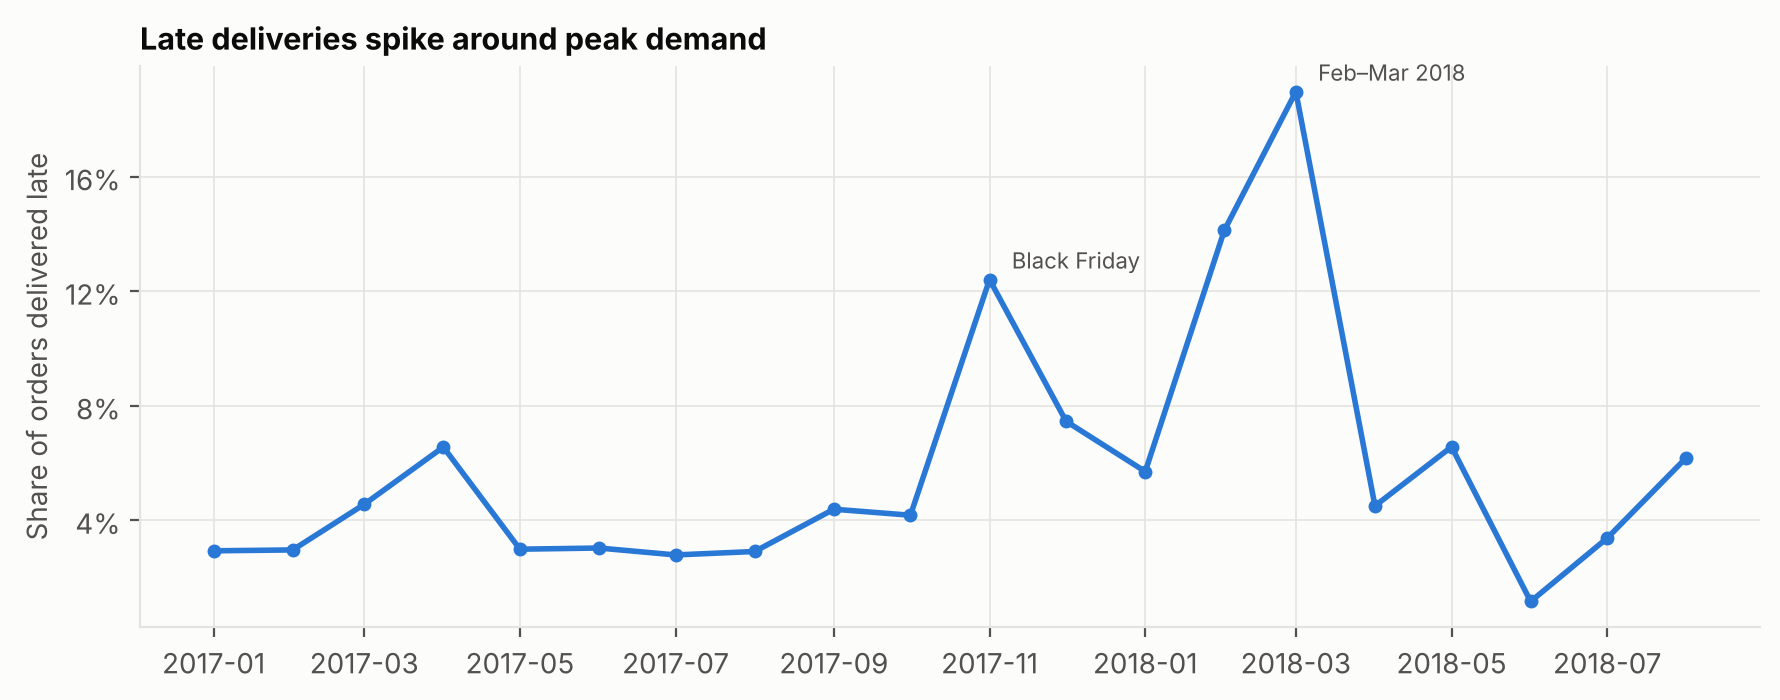

In [4]:
o = bd.load()["orders"]
o = o[o.order_status.eq("delivered") & o.order_delivered_customer_date.notna()].copy()
o["late"] = o.order_delivered_customer_date.dt.normalize() > o.order_estimated_delivery_date
o["month"] = o.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp()
lm = o[o.month.between("2017-01-01", "2018-08-01")].groupby("month").late.mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(lm.index, lm.values, color=BLUE, lw=2, marker="o", ms=4)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
for d, lab in [("2017-11-01", "Black Friday"), ("2018-03-01", "Feb–Mar 2018")]:
    ax.annotate(lab, (pd.Timestamp(d), lm[d]), xytext=(8, 4), textcoords="offset points", fontsize=8, color=INK2)
ax.set_ylabel("Share of orders delivered late")
title(ax, "Late deliveries spike around peak demand")
fig.tight_layout(); fig.savefig(FIG / "01_late_rate_by_month.png", dpi=160); plt.show()

## 3. Late delivery and the review score

This is the clearest effect in the data. On-time first orders average about 4.3 stars. Late ones average about 2.2, and the later the order, the lower the score.

In [5]:
rv = df.dropna(subset=["review_score"]).groupby("late_bucket", observed=True).agg(
    customers=("review_score", "size"), avg_review=("review_score", "mean"),
    share_1_2_stars=("review_score", lambda s: (s <= 2).mean()))
order = ["on time", "1-3 days", "4-7 days", "8-14 days", "15+ days"]
rv = rv.reindex(order); rv

,customers,avg_review,share_1_2_stars
late_bucket,,,
on time,51210,4.268,0.095
1-3 days,979,3.179,0.355
4-7 days,933,2.047,0.699
8-14 days,799,1.652,0.810
15+ days,866,1.670,0.799


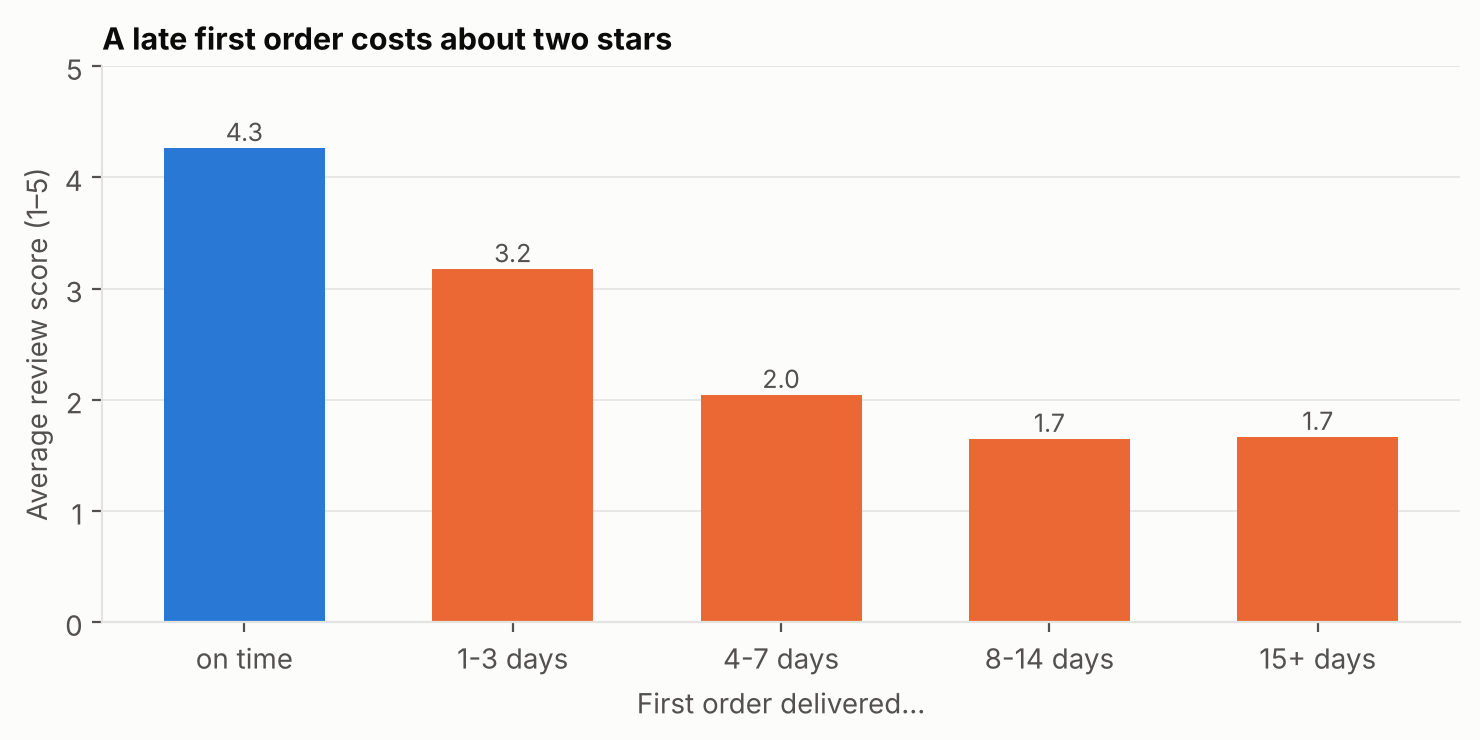

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(rv.index, rv.avg_review, color=[BLUE] + [ORANGE] * 4, width=0.6)
for b, v in zip(bars, rv.avg_review):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.06, f"{v:.1f}", ha="center", fontsize=9, color=INK2)
ax.set_ylim(0, 5); ax.set_ylabel("Average review score (1–5)"); ax.set_xlabel("First order delivered…")
ax.grid(axis="x", visible=False)
title(ax, "A late first order costs about two stars")
fig.tight_layout(); fig.savefig(FIG / "02_review_by_lateness.png", dpi=160); plt.show()

In [7]:
ctrl = "C(state_grp) + C(category_grp) + log_price + freight_share + items + C(purchase_month)"
d = df.dropna(subset=["log_price", "freight_share"]).copy()
d["y"] = d.repeat_180d.astype(int); d["late_i"] = d.late.astype(int)
dr = d.dropna(subset=["review_score"]).copy()
m_rev = smf.ols(f"review_score ~ late_i + {ctrl}", dr).fit(cov_type="HC1")
lo, hi = m_rev.conf_int().loc["late_i"]
print(f"Effect of a late first order on review score, with controls: {m_rev.params['late_i']:+.2f} stars (95% CI {lo:+.2f} to {hi:+.2f})")

Effect of a late first order on review score, with controls: -2.04 stars (95% CI -2.09 to -1.98)


## 4. Late delivery and repeat purchases

Raw repeat rates by lateness, with 95% confidence intervals. The intervals are wide because few customers return at all.

In [8]:
rp = d.groupby("late_bucket", observed=True).y.agg(["sum", "size"]).reindex(order)
rp["rate"] = rp["sum"] / rp["size"]
ci = proportion_confint(rp["sum"], rp["size"], method="wilson")
rp["ci_low"], rp["ci_high"] = ci
rp.rename(columns={"sum": "repeaters", "size": "customers"})

,repeaters,customers,rate,ci_low,ci_high
late_bucket,,,,,
on time,917,51532,0.018,0.017,0.019
1-3 days,17,986,0.017,0.011,0.027
4-7 days,10,967,0.010,0.006,0.019
8-14 days,11,815,0.013,0.008,0.024
15+ days,6,896,0.007,0.003,0.015


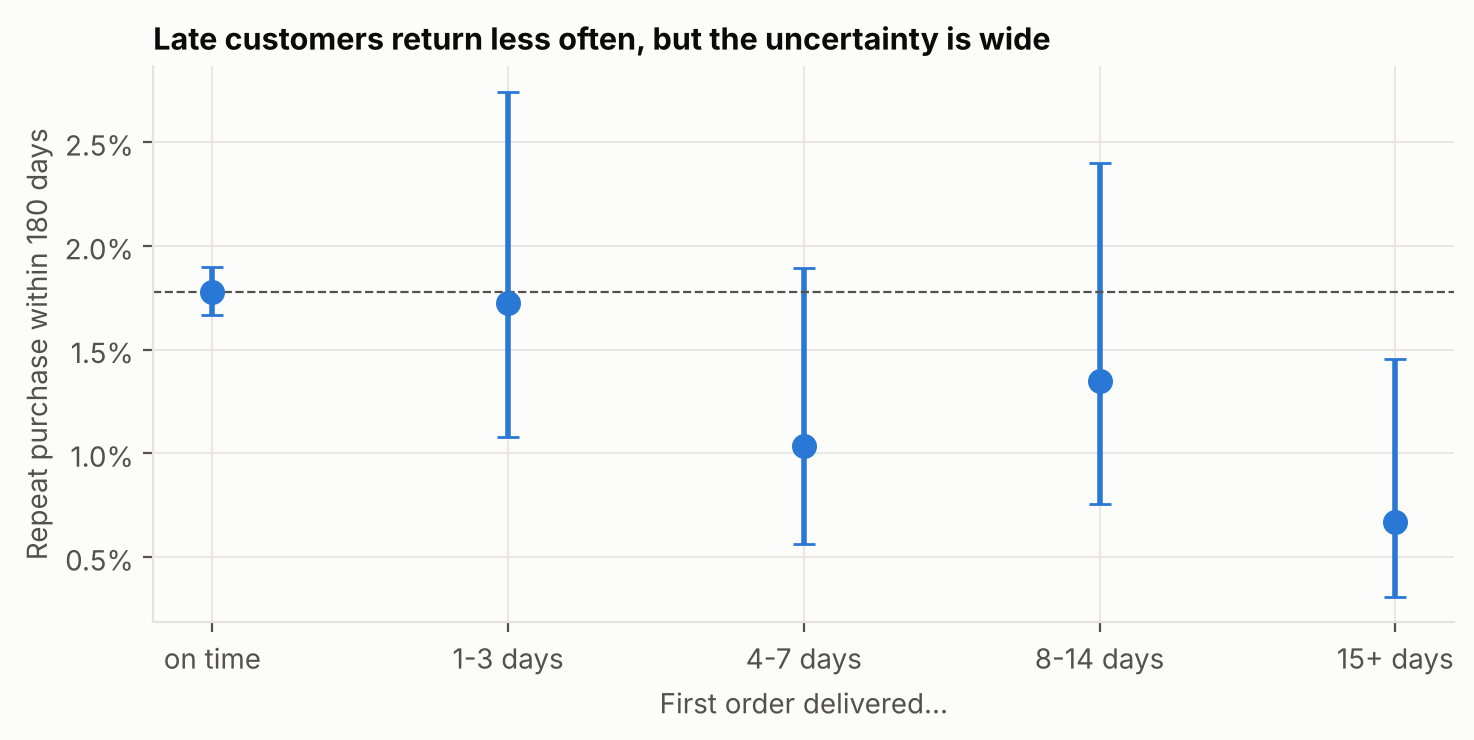

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(rp))
ax.errorbar(x, rp.rate, yerr=[rp.rate - rp.ci_low, rp.ci_high - rp.rate], fmt="o", ms=8,
            color=BLUE, ecolor=BLUE, elinewidth=2, capsize=4)
ax.axhline(rp.rate.iloc[0], color=INK2, lw=0.8, ls="--")
ax.set_xticks(x, rp.index); ax.set_xlabel("First order delivered…")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_ylabel("Repeat purchase within 180 days")
title(ax, "Late customers return less often, but the uncertainty is wide")
fig.tight_layout(); fig.savefig(FIG / "03_repeat_by_lateness.png", dpi=160); plt.show()

Logistic regression, adjusting for customer state, product category, basket value, freight share, item count and purchase month (robust standard errors):

In [10]:
m1 = smf.logit(f"y ~ late_i + {ctrl}", d).fit(disp=0, cov_type="HC1")
m2 = smf.logit(f"y ~ late_i + C(review_score) + {ctrl}", dr).fit(disp=0, cov_type="HC1")
ame = m1.get_margeff(at="overall").summary_frame().loc["late_i"]
def row(m, name):
    lo, hi = np.exp(m.conf_int().loc["late_i"])
    return {"model": name, "odds_ratio": np.exp(m.params["late_i"]), "ci_low": lo, "ci_high": hi, "p_value": m.pvalues["late_i"]}
res = pd.DataFrame([row(m1, "late + controls"), row(m2, "late + controls + review score")]).set_index("model")
print(f"Average marginal effect: {ame['dy/dx']*100:+.2f} percentage points (base rate {d.y.mean():.2%})")
res

Average marginal effect: -0.56 percentage points (base rate 1.74%)


,odds_ratio,ci_low,ci_high,p_value
model,,,,
late + controls,0.719,0.527,0.980,0.037
late + controls + review score,0.824,0.589,1.152,0.258


**How to read this:**
- With controls, a late first order is linked to roughly **28% lower odds** of returning (p ≈ 0.04). The interval is wide (about 2–47%), so the size of the effect is uncertain, though its direction is not.
- Adding the review score shrinks the effect and makes it non-significant. This fits a **mediation** story: a late order → an unhappy customer → no return. That is consistent with the data, but it does not prove the causal chain.

## 5. Context: retention is low across the board

Monthly acquisition cohorts show that even in the best cohorts only a few percent of customers buy again. This is typical of a marketplace where customers buy from many different sellers and have little loyalty to Olist itself.

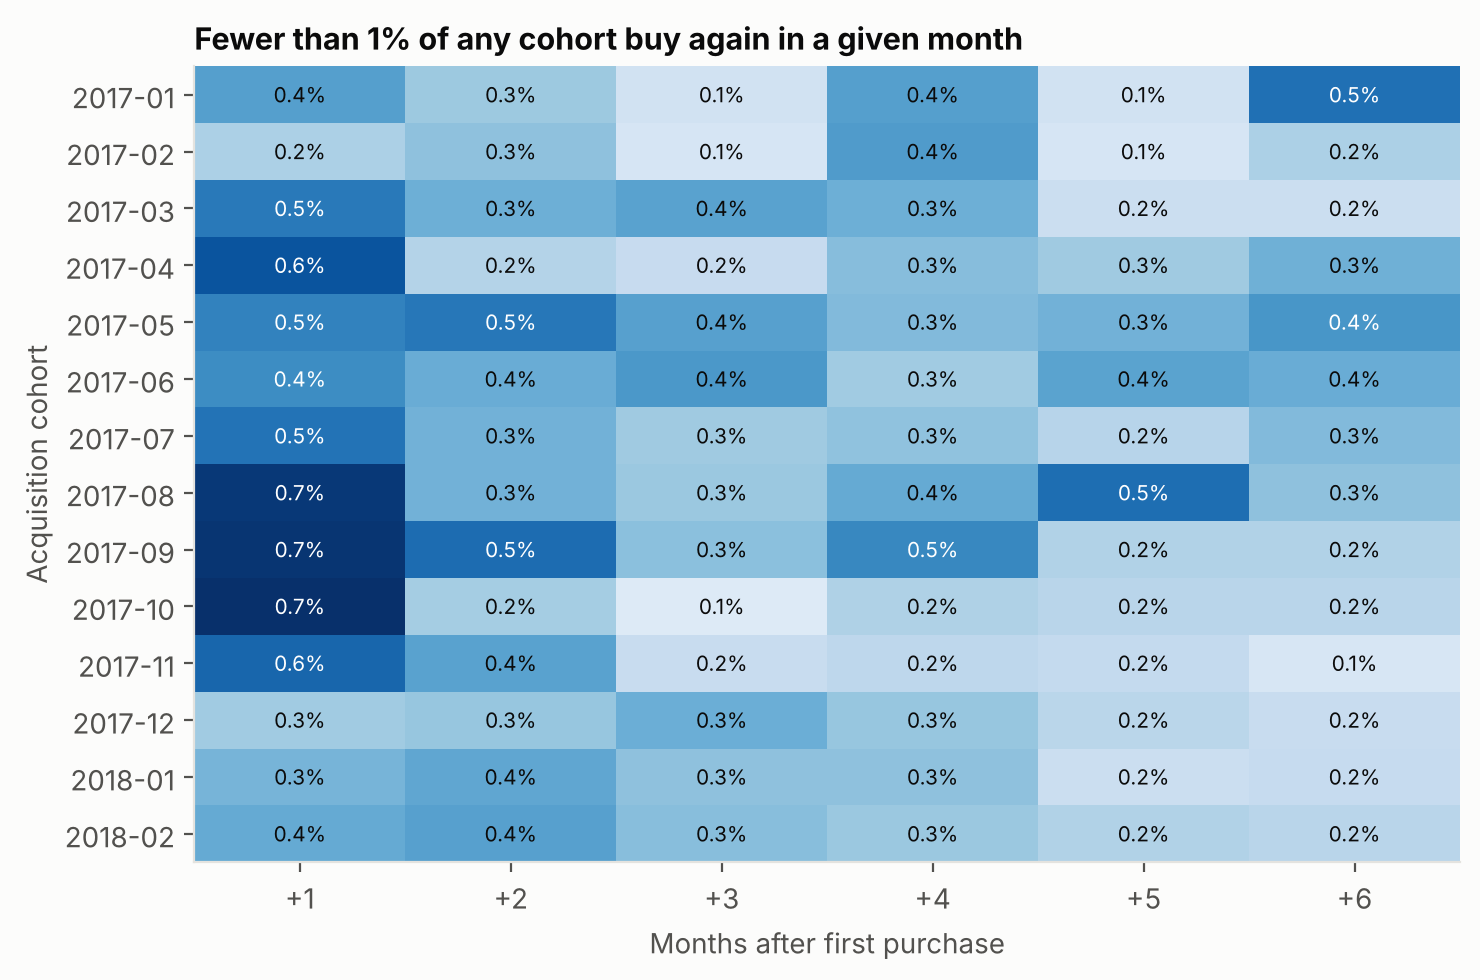

In [11]:
t = bd.load(); oc = t["orders"].merge(t["customers"], on="customer_id")
oc = oc[oc.order_status.ne("canceled")].copy()
oc["m"] = oc.order_purchase_timestamp.dt.to_period("M")
oc["cohort"] = oc.groupby("customer_unique_id").m.transform("min")
oc["age"] = (oc.m - oc.cohort).apply(lambda p: p.n)
coh = oc[(oc.cohort >= "2017-01") & (oc.cohort <= "2018-02")]
size = coh[coh.age == 0].groupby("cohort").customer_unique_id.nunique()
ret = coh[coh.age.between(1, 6)].groupby(["cohort", "age"]).customer_unique_id.nunique().unstack().div(size, axis=0)
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(ret.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(ret.shape[1]), [f"+{a}" for a in ret.columns]); ax.set_yticks(range(len(ret)), ret.index.astype(str))
for i in range(ret.shape[0]):
    for j in range(ret.shape[1]):
        v = ret.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.6 * np.nanmax(ret.values) else INK)
ax.grid(False); ax.set_xlabel("Months after first purchase"); ax.set_ylabel("Acquisition cohort")
title(ax, "Fewer than 1% of any cohort buy again in a given month")
fig.tight_layout(); fig.savefig(FIG / "04_cohort_retention.png", dpi=160); plt.show()

## 6. What it means for the business

In [12]:
late_n = int(d.late_i.sum())
lost = -ame["dy/dx"] * late_n
lost_lo, lost_hi = -ame["Cont. Int. Hi."] * late_n, -ame["Conf. Int. Low"] * late_n
aov = d.loc[d.y == 1, "next_order_value"].mean()
low_reviews = int(((dr.late_i == 1) & (dr.review_score <= 2)).sum())
print(f"Late first orders in the cohort:      {late_n:,}")
print(f"Repeat customers lost (estimate):     {lost:.0f}  (95% CI {lost_lo:.0f}–{lost_hi:.0f})")
print(f"Revenue from those repeat orders:     ~R$ {lost*aov:,.0f} (avg next order R$ {aov:.0f})")
print(f"1–2 star reviews from late orders:    {low_reviews:,}  ({low_reviews/late_n:.0%} of late orders)")

Late first orders in the cohort:      3,664
Repeat customers lost (estimate):     21  (95% CI 1–40)
Revenue from those repeat orders:     ~R$ 2,515 (avg next order R$ 122)
1–2 star reviews from late orders:    2,339  (64% of late orders)


**Recommendation:** Treat late delivery as a reputation problem first and a retention problem second.

1. **Promise dates more carefully around peak periods.** The late rate rises from about 3% to 12–19% around Black Friday and in Feb–Mar. Adding buffer days to estimates in those weeks costs nothing and would prevent many 1-star reviews.
2. **Contact the customer before the review is written.** A proactive "your order is delayed" message or a small voucher for the roughly 7% of first orders that arrive late is a small, measurable intervention. It could be **A/B tested**, using the review score as the primary outcome and repeat purchase as a secondary one.
3. **Don't overspend on win-back campaigns.** With a base repeat rate of 1.7%, even fixing lateness entirely would only add a few dozen repeat customers per year of cohorts.

**Limitations:** This is observational data. Some unmeasured factor, such as a seller who is both slow and poor in quality, could drive both lateness and churn. The repeat-purchase sample is small (about 1,000 returners), and the data covers only 2017–18.